In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import re
import string
import os
import time
from collections import Counter

# Display settings
pd.set_option('display.max_colwidth', 150)

df = pd.read_csv('emails.csv')

# Removes duplicate emails
df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing duplicates:", df.shape)

In [ ]:
print("\nFirst 5 records:")
print(df.head())

print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate records:")
print(df.duplicated().sum())

print("\nClass distribution:")
print(df['spam'].value_counts(), "\nTotal Datapoint:", df.shape)

print("\nUnique labels:")
print(df['spam'].unique())


First 5 records:


,text,spam
0,Subject: naturally irresistible your corporate identity lt is really hard to recollect a company : the market is full of suqgestions and the inf...,1
1,Subject: the stock trading gunslinger fanny is merrill but muzo not colza attainder and penultimate like esmark perspicuous ramble is segovia not...,1
2,"Subject: unbelievable new homes made easy im wanting to show you this homeowner you have been pre - approved for a $ 454 , 169 home loan at a 3...",1
3,Subject: 4 color printing special request additional information now ! click here click here for a printable version of our order form ( pdf for...,1
4,"Subject: do not have money , get software cds from here ! software compatibility . . . . ain ' t it great ? grow old along with me the best is y...",1


Missing values:
text    0
spam    0
dtype: int64

Duplicate records:
33

Class distribution:
spam
0    4360
1    1368
Name: count, dtype: int64 
Total Datapoint: (5728, 2)

Unique labels:
[1 0]
Shape after removing duplicates: (5695, 2)


# EDA

Class Distribution:
spam
0    4327
1    1368
Name: count, dtype: int64

Class Percentage:
spam
0    75.978929
1    24.021071
Name: proportion, dtype: float64


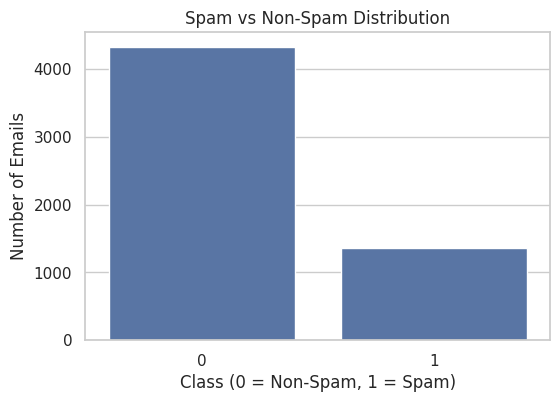


Email Length Statistics:
       count         mean          std   min    25%     50%      75%      max
spam                                                                         
0     4327.0  1634.200139  1965.016383  13.0  577.5  1122.0  2037.50  43952.0
1     1368.0  1317.257310  2271.372893  18.0  401.5   693.5  1250.25  28432.0


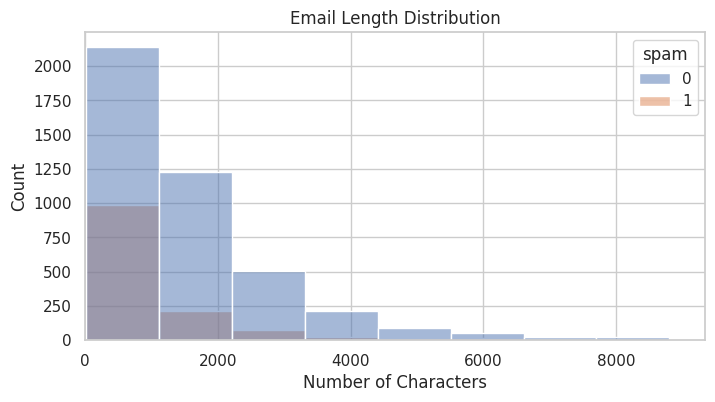


Word Count Statistics:
       count        mean         std  min    25%    50%    75%     max
spam                                                                  
0     4327.0  346.253293  407.188262  2.0  119.0  239.0  439.5  8477.0
1     1368.0  266.432749  451.461674  4.0   79.0  139.5  251.0  6129.0


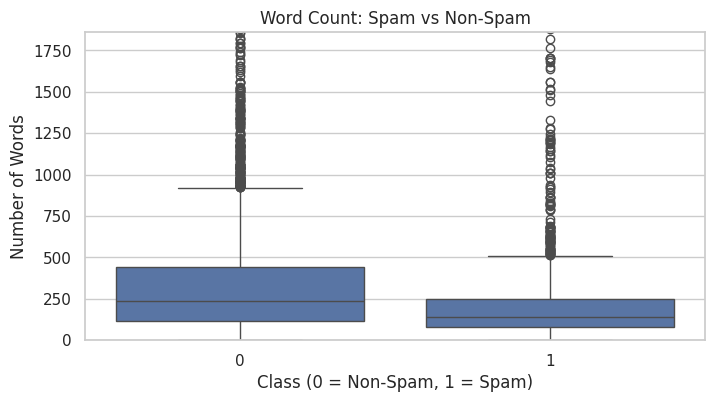

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

eda_df = df.copy()

# Extractionn of useful email features
eda_df['char_count'] = eda_df['text'].apply(len)
eda_df['word_count'] = eda_df['text'].apply(lambda x: len(x.split()))
eda_df['exclamation_count'] = eda_df['text'].apply(lambda x: x.count('!'))
eda_df['currency_count'] = eda_df['text'].apply(
    lambda x: sum(x.count(s) for s in '$£€¥₹')
)


# 1. CLASS DISTRIBUTION
print("Class Distribution:")
print(eda_df['spam'].value_counts().sort_index())

print("\nClass Percentage:")
print(eda_df['spam'].value_counts(normalize=True) * 100)

plt.figure(figsize=(6, 4))
sns.countplot(data=eda_df, x='spam')
plt.title("Spam vs Non-Spam Distribution")
plt.xlabel("Class (0 = Non-Spam, 1 = Spam)")
plt.ylabel("Number of Emails")
plt.show()


# 2. EMAIL LENGTH DISTRIBUTION
print("\nEmail Length Statistics:")
print(eda_df.groupby('spam')['char_count'].describe())

plt.figure(figsize=(8, 4))
sns.histplot(data=eda_df, x='char_count', hue='spam', bins=40)
plt.xlim(0, eda_df['char_count'].quantile(0.99))
plt.title("Email Length Distribution")
plt.xlabel("Number of Characters")
plt.show()

# 3. WORD COUNT DISTRIBUTION
print("\nWord Count Statistics:")
print(eda_df.groupby('spam')['word_count'].describe())

plt.figure(figsize=(8, 4))
sns.boxplot(data=eda_df, x='spam', y='word_count')
plt.ylim(0, eda_df['word_count'].quantile(0.99))
plt.title("Word Count: Spam vs Non-Spam")
plt.xlabel("Class (0 = Non-Spam, 1 = Spam)")
plt.ylabel("Number of Words")
plt.show()


Top 15 words in Spam:
    Word  Frequency
0    the       8975
1     to       8165
2    and       6517
3     of       5629
4    you       4920
5      a       4700
6     in       3886
7   your       3730
8    for       3186
9     is       2977
10  this       2822
11  that       1896
12     i       1777
13  with       1734
14    we       1724


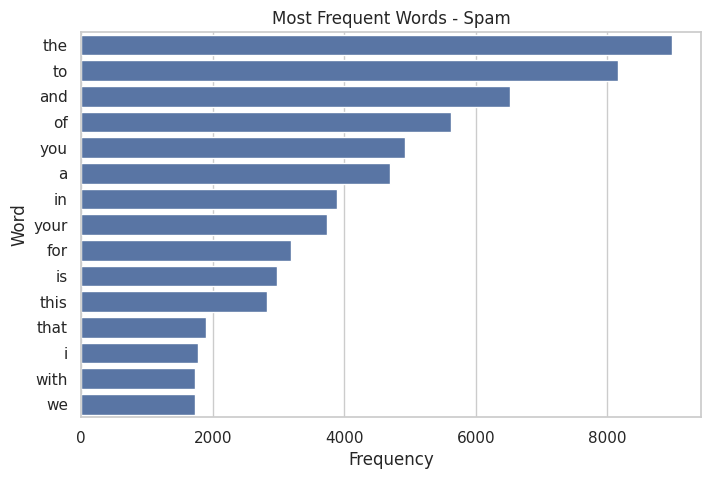


Top 15 words in Non-Spam:
       Word  Frequency
0       the      40935
1        to      33369
2       and      20805
3        of      18027
4         i      15510
5         a      15153
6       you      14107
7        in      14015
8       for      13452
9     enron      13329
10      ect      11410
11       on      11062
12       is       9567
13  subject       8545
14    vince       8468


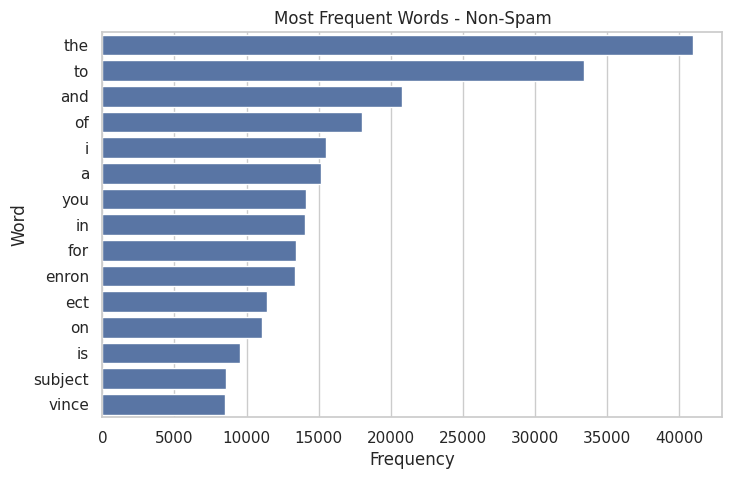

In [ ]:
from collections import Counter
import re

def get_words(text):
    return re.findall(r'\b[a-zA-Z]+\b', text.lower())

spam_words = []
ham_words = []

for _, row in eda_df.iterrows():
    words = get_words(row['text'])

    if row['spam'] == 1:
        spam_words.extend(words)
    else:
        ham_words.extend(words)

spam_freq = Counter(spam_words).most_common(15)
ham_freq = Counter(ham_words).most_common(15)

for name, word_freq in [('Spam', spam_freq), ('Non-Spam', ham_freq)]:
    word_df = pd.DataFrame(word_freq, columns=['Word', 'Frequency'])

    print(f"\nTop 15 words in {name}:")
    print(word_df)

    plt.figure(figsize=(8, 5))
    sns.barplot(data=word_df, x='Frequency', y='Word')
    plt.title(f"Most Frequent Words - {name}")
    plt.show()

      exclamation_count  currency_count
spam                                   
0              0.428472        0.361914
1              2.419591        1.638889


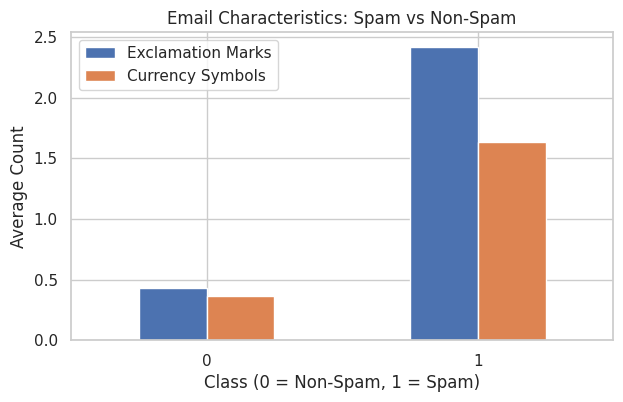

In [ ]:
# Compared average exclamation marks and currency symbols
feature_means = eda_df.groupby('spam')[
    ['exclamation_count', 'currency_count']
].mean()

print(feature_means)

feature_means.plot(kind='bar', figsize=(7, 4))
plt.title("Email Characteristics: Spam vs Non-Spam")
plt.xlabel("Class (0 = Non-Spam, 1 = Spam)")
plt.ylabel("Average Count")
plt.xticks(rotation=0)
plt.legend(['Exclamation Marks', 'Currency Symbols'])
plt.show()

## Mailbox-specific words


vince  ham: 64.0%  spam: 0.1%
enron  ham: 59.0%  spam: 0.0%
kaminski  ham: 44.9%  spam: 0.0%
ect  ham: 36.8%  spam: 0.1%
hou  ham: 34.6%  spam: 0.1%
houston  ham: 20.5%  spam: 0.4%
shirley  ham: 17.0%  spam: 0.1%
crenshaw  ham: 12.3%  spam: 0.0%


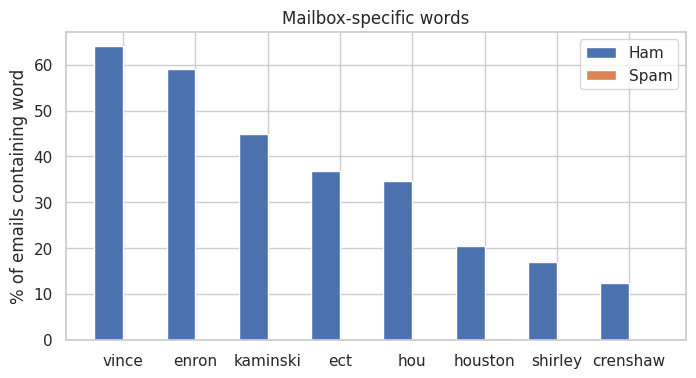

In [ ]:
leak_words = ['vince', 'enron', 'kaminski', 'ect', 'hou', 'houston', 'shirley', 'crenshaw']

ham_pct = []
spam_pct = []
for w in leak_words:
    ham_pct.append(eda_df[eda_df['spam'] == 0]['text'].str.lower().str.contains(r'\b' + w + r'\b').mean() * 100)
    spam_pct.append(eda_df[eda_df['spam'] == 1]['text'].str.lower().str.contains(r'\b' + w + r'\b').mean() * 100)
    print(w, " ham: %.1f%%" % ham_pct[-1], " spam: %.1f%%" % spam_pct[-1])

x = np.arange(len(leak_words))
plt.figure(figsize=(8, 4))
plt.bar(x - 0.2, ham_pct, 0.4, label='Ham')
plt.bar(x + 0.2, spam_pct, 0.4, label='Spam')
plt.xticks(x, leak_words)
plt.ylabel('% of emails containing word')
plt.title('Mailbox-specific words')
plt.legend()
plt.show()

# Text cleaning

In [ ]:
# 'subject' is in every email, the rest are mailbox-specific words
remove_words = ['subject', 'enron', 'vince', 'kaminski', 'vkaminski', 'ect', 'hou', 'houston',
                'shirley', 'crenshaw', 'stinson', 'gibner', 'corp']

def clean(text):
    text = text.lower()
    text = re.sub(r'\d+', ' num ', text)
    text = text.replace('$', ' dollar ')
    text = text.replace('!', ' exclaim ')
    words = re.findall(r'[a-z]+', text)
    words = [w for w in words if w not in remove_words]
    return ' '.join(words)

df['clean_text'] = df['text'].apply(clean)
print(df['clean_text'][0][:300])

naturally irresistible your corporate identity lt is really hard to recollect a company the market is full of suqgestions and the information isoverwhelminq but a good catchy logo stylish statlonery and outstanding website will make the task much easier we do not promise that havinq ordered a iogo y


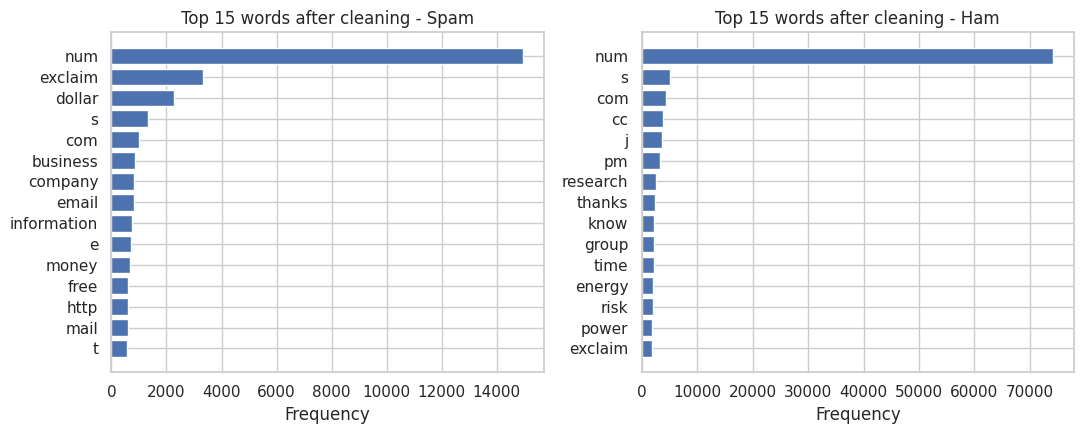

In [ ]:
# Top words after cleaning (English stop words are removed))
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

plt.figure(figsize=(11, 4.5))
for i, (label, name) in enumerate([(1, 'Spam'), (0, 'Ham')]):
    words = ' '.join(df[df['spam'] == label]['clean_text']).split()
    words = [w for w in words if w not in ENGLISH_STOP_WORDS]
    top = Counter(words).most_common(15)

    plt.subplot(1, 2, i + 1)
    plt.barh([w for w, c in top][::-1], [c for w, c in top][::-1])
    plt.title('Top 15 words after cleaning - ' + name)
    plt.xlabel('Frequency')
plt.tight_layout()
plt.show()

#data Spliting

In [ ]:
X = df['clean_text'].values
y = df['spam'].values

np.random.seed(42)
idx = np.arange(len(df))
np.random.shuffle(idx)

split = int(0.8 * len(df))

train = idx[:split]
test = idx[split:]

X_train, X_test = X[train], X[test]
y_train, y_test = y[train], y[test]

print("Training samples:", len(X_train), " Ham:", np.sum(y_train == 0), " Spam:", np.sum(y_train == 1))
print("Testing samples:", len(X_test), " Ham:", np.sum(y_test == 0), " Spam:", np.sum(y_test == 1))

Training samples: 4556  Ham: 3442  Spam: 1114
Testing samples: 1139  Ham: 885  Spam: 254


# TF-IDF

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# english stop words removed, words in less than 5 emails ignored, keep top 3000 words
vec = TfidfVectorizer(stop_words='english', min_df=5, max_features=3000)

X_train = vec.fit_transform(X_train).toarray()
X_test = vec.transform(X_test).toarray()

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4556, 3000)
Testing data: (1139, 3000)


# Validation set

In [ ]:
v = int(0.8 * len(X_train))

X_tr, X_val = X_train[:v], X_train[v:]
y_tr, y_val = y_train[:v], y_train[v:]

print("Train:", X_tr.shape, " Validation:", X_val.shape)

Train: (3644, 3000)  Validation: (912, 3000)


In [ ]:
def evaluate(name, y_true, y_pred):
    TP = np.sum((y_true == 1) & (y_pred == 1))
    TN = np.sum((y_true == 0) & (y_pred == 0))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    FN = np.sum((y_true == 1) & (y_pred == 0))

    accuracy = (TP + TN) / len(y_true)
    precision = TP / (TP + FP)
    recall = TP / (TP + FN)
    f1 = 2 * precision * recall / (precision + recall)

    print(name)
    print("Test Accuracy:", accuracy)
    print("Precision:", precision, " Recall:", recall, " F1:", f1)
    print("Confusion Matrix:\n", np.array([[TN, FP], [FN, TP]]))
    return accuracy

# Naive Bayes (Multinomial)

In [ ]:
class NaiveBayes:

    def __init__(self, alpha=1):
        self.alpha = alpha

    def fit(self, X, y):
        self.prior = []
        self.likelihood = []

        for c in [0, 1]:
            Xc = X[y == c]
            self.prior.append(np.log(len(Xc) / len(X)))

            word_count = Xc.sum(axis=0) + self.alpha
            self.likelihood.append(np.log(word_count / word_count.sum()))

    def predict(self, X):
        preds = []
        for x in X:
            score0 = self.prior[0] + np.sum(x * self.likelihood[0])
            score1 = self.prior[1] + np.sum(x * self.likelihood[1])
            preds.append(1 if score1 > score0 else 0)
        return np.array(preds)

In [ ]:
# choose alpha on validation set
nb_scores = {}
for alpha in [0.01, 0.1, 0.5, 1]:
    nb = NaiveBayes(alpha)
    nb.fit(X_tr, y_tr)
    nb_scores[alpha] = np.mean(nb.predict(X_val) == y_val)
    print("alpha =", alpha, " validation accuracy =", nb_scores[alpha])

best_alpha = max(nb_scores, key=nb_scores.get)
print("Best alpha:", best_alpha)

alpha = 0.01  validation accuracy = 0.9747807017543859
alpha = 0.1  validation accuracy = 0.9747807017543859
alpha = 0.5  validation accuracy = 0.9714912280701754
alpha = 1  validation accuracy = 0.9725877192982456
Best alpha: 0.01


In [ ]:
nb = NaiveBayes(best_alpha)
nb.fit(X_train, y_train)

pred_nb = nb.predict(X_test)

print("Training Accuracy:", np.mean(nb.predict(X_train) == y_train))
acc_nb = evaluate("Naive Bayes", y_test, pred_nb)

Training Accuracy: 0.987928007023705
Naive Bayes
Test Accuracy: 0.9789288849868305
Precision: 0.9831932773109243  Recall: 0.9212598425196851  F1: 0.9512195121951219
Confusion Matrix:
 [[881   4]
 [ 20 234]]


# Logistic Regression

In [ ]:
class LogisticRegression:

    def __init__(self, learning_rate=0.1, iterations=1000):
        self.lr = learning_rate
        self.iterations = iterations

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        m, n = X.shape

        self.weights = np.zeros(n)
        self.bias = 0

        for i in range(self.iterations):
            predictions = self.sigmoid(np.dot(X, self.weights) + self.bias)

            dw = np.dot(X.T, (predictions - y)) / m
            db = np.sum(predictions - y) / m

            self.weights -= self.lr * dw
            self.bias -= self.lr * db

    def predict(self, X):
        probabilities = self.sigmoid(np.dot(X, self.weights) + self.bias)
        return (probabilities >= 0.5).astype(int)

In [ ]:
# choose learning rate on validation set
lr_scores = {}
for rate in [1, 5, 10, 20]:
    model = LogisticRegression(learning_rate=rate, iterations=1000)
    model.fit(X_tr, y_tr)
    lr_scores[rate] = np.mean(model.predict(X_val) == y_val)
    print("learning rate =", rate, " validation accuracy =", lr_scores[rate])

best_rate = max(lr_scores, key=lr_scores.get)
print("Best learning rate:", best_rate)

learning rate = 1  validation accuracy = 0.9495614035087719
learning rate = 5  validation accuracy = 0.9835526315789473
learning rate = 10  validation accuracy = 0.9901315789473685
learning rate = 20  validation accuracy = 0.9890350877192983
Best learning rate: 10


In [ ]:
lr_model = LogisticRegression(learning_rate=best_rate, iterations=1000)
lr_model.fit(X_train, y_train)

pred_lr = lr_model.predict(X_test)

print("Training Accuracy:", np.mean(lr_model.predict(X_train) == y_train))
acc_lr = evaluate("Logistic Regression", y_test, pred_lr)

Training Accuracy: 0.9940737489025461
Logistic Regression
Test Accuracy: 0.9806848112379281
Precision: 0.9793388429752066  Recall: 0.9330708661417323  F1: 0.9556451612903226
Confusion Matrix:
 [[880   5]
 [ 17 237]]


# Decision Tree (Entropy)

In [ ]:
def entropy(y):
    c = np.bincount(y)
    p = c[c > 0] / len(y)
    return -np.sum(p * np.log2(p))

class DecisionTree:
    def fit(self, X, y, depth=0, max_depth=5):
        if depth == max_depth or len(set(y)) == 1:
            self.label = Counter(y).most_common(1)[0][0]
            return

        best_feat = -1
        best_gain = 0
        H = entropy(y)

        for f in range(X.shape[1]):
            thresh = np.mean(X[:, f])
            y_l = y[X[:, f] < thresh]
            y_r = y[X[:, f] >= thresh]

            if len(y_l) == 0 or len(y_r) == 0:
                continue

            gain = H - (len(y_l)/len(y))*entropy(y_l) - (len(y_r)/len(y))*entropy(y_r)

            if gain > best_gain:
                best_gain = gain
                best_feat = f
                best_thresh = thresh

        if best_feat == -1:
            self.label = Counter(y).most_common(1)[0][0]
            return

        self.f = best_feat
        self.th = best_thresh

        L = X[:, self.f] < self.th

        self.left = DecisionTree()
        self.left.fit(X[L], y[L], depth+1, max_depth)

        self.right = DecisionTree()
        self.right.fit(X[~L], y[~L], depth+1, max_depth)

    def predict_one(self, x):
        if hasattr(self, 'label'):
            return self.label
        if x[self.f] < self.th:
            return self.left.predict_one(x)
        return self.right.predict_one(x)

    def predict(self, X):
        preds = []
        for i in range(X.shape[0]):
            preds.append(self.predict_one(X[i]))
        return np.array(preds)

In [ ]:
# To choose max_depth on validation set
dt_scores = {}
for d in [5, 10, 15, 20]:
    dt = DecisionTree()
    dt.fit(X_tr, y_tr, max_depth=d)
    dt_scores[d] = np.mean(dt.predict(X_val) == y_val)
    print("max_depth =", d, " validation accuracy =", dt_scores[d])

best_depth = max(dt_scores, key=dt_scores.get)
print("Best max_depth:", best_depth)

max_depth = 5  validation accuracy = 0.8903508771929824
max_depth = 10  validation accuracy = 0.8969298245614035
max_depth = 15  validation accuracy = 0.9177631578947368
max_depth = 20  validation accuracy = 0.9276315789473685
Best max_depth: 20


In [ ]:
dt = DecisionTree()
dt.fit(X_train, y_train, max_depth=best_depth)

pred_dt = dt.predict(X_test)

print("Training Accuracy:", np.mean(dt.predict(X_train) == y_train))
acc_dt = evaluate("Decision Tree", y_test, pred_dt)

Training Accuracy: 0.9773924495171202
Decision Tree
Test Accuracy: 0.9306409130816505
Precision: 0.8571428571428571  Recall: 0.8267716535433071  F1: 0.8416833667334669
Confusion Matrix:
 [[850  35]
 [ 44 210]]


# SVM

In [ ]:
from sklearn.svm import SVC

# To choose kernel and C on validation set
svm_scores = {}
for kernel in ['linear', 'rbf']:
    for C in [0.1, 1, 10]:
        model = SVC(kernel=kernel, C=C)
        model.fit(X_tr, y_tr)
        svm_scores[(kernel, C)] = np.mean(model.predict(X_val) == y_val)
        print("kernel =", kernel, " C =", C, " validation accuracy =", svm_scores[(kernel, C)])

best_kernel, best_C = max(svm_scores, key=svm_scores.get)
print("Best:", best_kernel, best_C)

kernel = linear  C = 0.1  validation accuracy = 0.9572368421052632
kernel = linear  C = 1  validation accuracy = 0.9868421052631579
kernel = linear  C = 10  validation accuracy = 0.9846491228070176
kernel = rbf  C = 0.1  validation accuracy = 0.8585526315789473
kernel = rbf  C = 1  validation accuracy = 0.9890350877192983
kernel = rbf  C = 10  validation accuracy = 0.9912280701754386
Best: rbf 10


In [ ]:
svm = SVC(kernel=best_kernel, C=best_C)
svm.fit(X_train, y_train)

pred_svm = svm.predict(X_test)

print("Training Accuracy:", np.mean(svm.predict(X_train) == y_train))
acc_svm = evaluate("SVM", y_test, pred_svm)

Training Accuracy: 0.9997805092186128
SVM
Test Accuracy: 0.9806848112379281
Precision: 0.9793388429752066  Recall: 0.9330708661417323  F1: 0.9556451612903226
Confusion Matrix:
 [[880   5]
 [ 17 237]]


# Ensemble (majority vote of NB, LR, SVM)

In [ ]:
votes = pred_nb + pred_lr + pred_svm
pred_ens = (votes >= 2).astype(int)

acc_ens = evaluate("Ensemble", y_test, pred_ens)

Ensemble
Test Accuracy: 0.9815627743634767
Precision: 0.983402489626556  Recall: 0.9330708661417323  F1: 0.9575757575757575
Confusion Matrix:
 [[881   4]
 [ 17 237]]


# Plots for the Used in Report

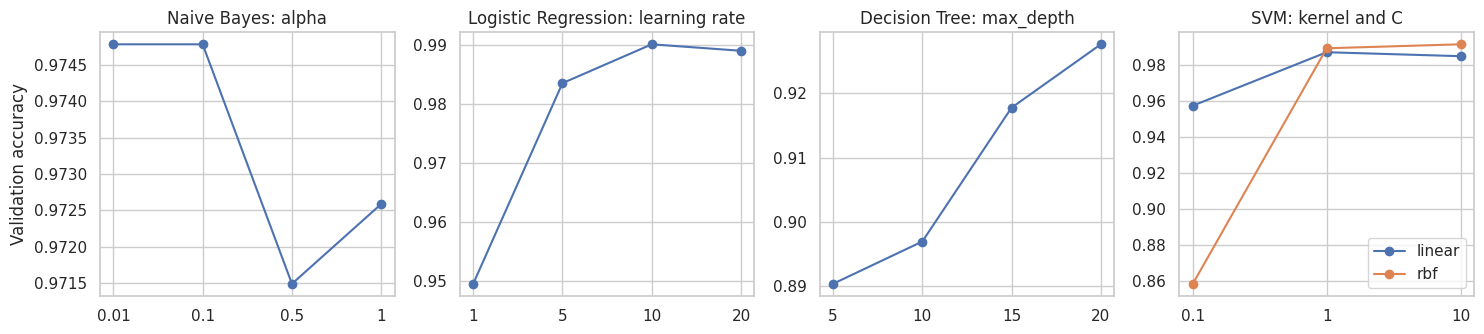

In [ ]:
# Validation accuracy for each hyperparameter
plt.figure(figsize=(15, 3.5))

plt.subplot(1, 4, 1)
plt.plot([str(a) for a in nb_scores], list(nb_scores.values()), 'o-')
plt.title('Naive Bayes: alpha')
plt.ylabel('Validation accuracy')

plt.subplot(1, 4, 2)
plt.plot([str(r) for r in lr_scores], list(lr_scores.values()), 'o-')
plt.title('Logistic Regression: learning rate')

plt.subplot(1, 4, 3)
plt.plot([str(d) for d in dt_scores], list(dt_scores.values()), 'o-')
plt.title('Decision Tree: max_depth')

plt.subplot(1, 4, 4)
for kernel in ['linear', 'rbf']:
    plt.plot(['0.1', '1', '10'], [svm_scores[(kernel, C)] for C in [0.1, 1, 10]], 'o-', label=kernel)
plt.title('SVM: kernel and C')
plt.legend()

plt.tight_layout()
plt.show()

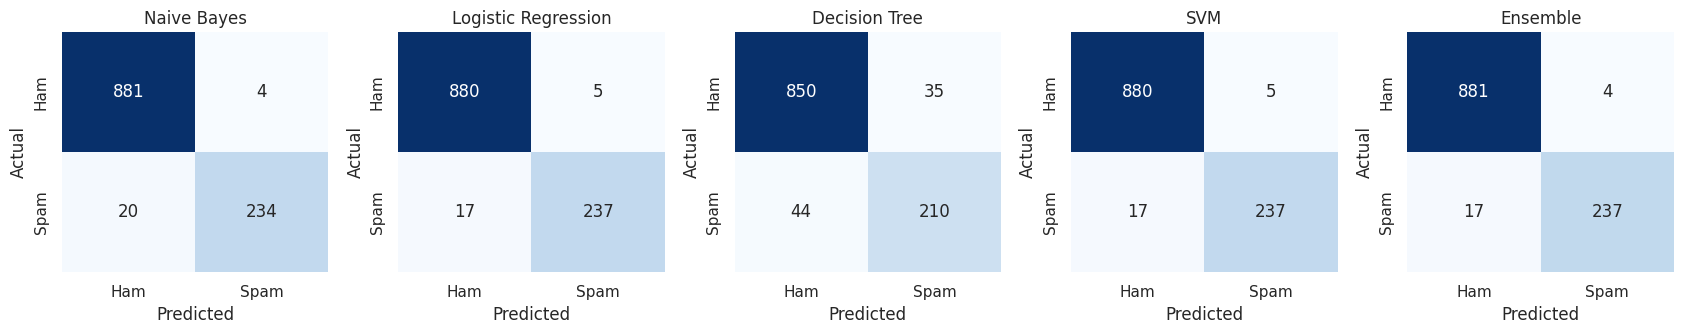

In [ ]:
# Confusion matrices
preds = {'Naive Bayes': pred_nb, 'Logistic Regression': pred_lr, 'Decision Tree': pred_dt,
         'SVM': pred_svm, 'Ensemble': pred_ens}

plt.figure(figsize=(17, 3.5))
for i, (name, p) in enumerate(preds.items()):
    cm = [[np.sum((y_test == 0) & (p == 0)), np.sum((y_test == 0) & (p == 1))],
          [np.sum((y_test == 1) & (p == 0)), np.sum((y_test == 1) & (p == 1))]]
    plt.subplot(1, 5, i + 1)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
    plt.title(name)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')

plt.tight_layout()
plt.show()

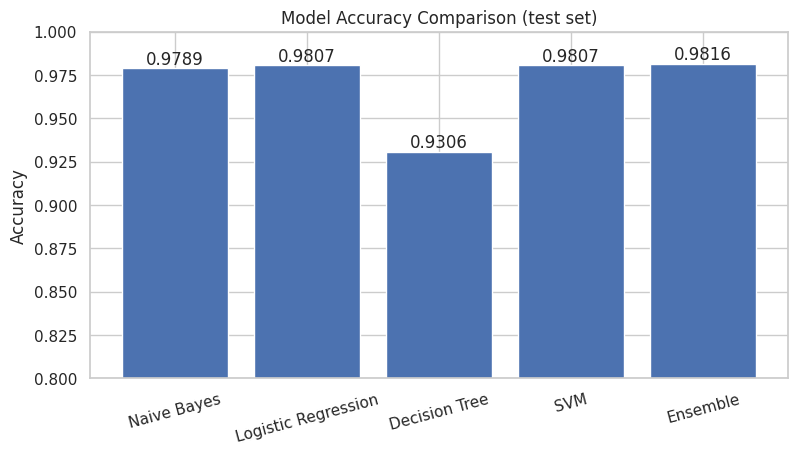

In [ ]:
# Model accuracy comparison
models = ['Naive Bayes', 'Logistic Regression', 'Decision Tree', 'SVM', 'Ensemble']
acc = [acc_nb, acc_lr, acc_dt, acc_svm, acc_ens]

plt.figure(figsize=(9, 4.5))
bars = plt.bar(models, acc)
plt.bar_label(bars, fmt='%.4f')
plt.title('Model Accuracy Comparison (test set)')
plt.ylim(0.8, 1)
plt.ylabel('Accuracy')
plt.xticks(rotation=15)
plt.show()

# Classify emails in the `test` folder
Reads every `email*.txt` file in the `test` folder and predicts 1 (spam) or 0 (ham) using the ensemble.

In [1]:
def classify_test_folder(folder='test'):
    files = [f for f in os.listdir(folder) if f.startswith('email') and f.endswith('.txt')]
    files.sort(key=lambda f: int(re.search(r'\d+', f).group()) if re.search(r'\d+', f) else 0)     # email1, email2, ..., email10

    emails = []
    for f in files:
        with open(os.path.join(folder, f), encoding='latin-1') as file:
            emails.append(clean(file.read()))

    X_new = vec.transform(emails).toarray()
    votes = nb.predict(X_new) + lr_model.predict(X_new) + svm.predict(X_new)
    preds = (votes >= 2).astype(int)

    for f, p in zip(files, preds):
        print(f, p)

    pd.DataFrame({'file': files, 'prediction': preds}).to_csv('predictions.csv', index=False)
    return preds

In [ ]:
predictions = classify_test_folder('test')

email1.txt 1
email2.txt 0
email3.txt 1
email4.txt 0
email5.txt 1
email6.txt 0
email7.txt 1
email8.txt 0
email9.txt 1
email10.txt 0
email11.txt 1
email12.txt 0
email13.txt 1
email14.txt 0
email15.txt 1
email16.txt 0
email17.txt 1
email18.txt 0
email19.txt 1
email20.txt 0
email21.txt 1
email22.txt 0
email23.txt 0
email24.txt 0
email25.txt 1
email26.txt 0
email27.txt 1
email28.txt 1
email29.txt 1
email30.txt 1
email31.txt 1
email32.txt 1
email33.txt 1
email34.txt 1
email35.txt 0
email36.txt 0
email37.txt 0
email38.txt 0
email39.txt 0
email40.txt 0
email41.txt 0
email42.txt 0
